# M10-1 | Writing the VPU's Hardware Constraints as a Quantizer: `MyVPUQuantizer`

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/bobondemon/pt2e_quantize_and_deploy/blob/main/en/m10_custom_backend/01_vpu_quantizer.ipynb)

The Quantizers in M03 were rules made up for teaching; a real backend Quantizer translates hardware constraints into annotations. This chapter invents a VPU, and its constraints and implementation are in [`vpu_quantizer.py`](vpu_quantizer.py) in the same directory (the project's backend itself, not a torchao API); read it side by side with this notebook.

- **A.** Which PT2E mechanism implements each of the eight constraints, and where in `vpu_quantizer.py` it lives.
- **B.** The scale must be a power of 2: how a custom observer changes the scale, and what it costs.
- **C.** `validate()`: a graph with dynamic batch is rejected inside `prepare_pt2e`.
- **D.** TinyConvNet on the VPU: which tensors are forced to use the same scale.
- **E.** After `convert_pt2e`: confirm the numbers on the Q/DQ graph.

In [ ]:
#| include: false
# On Google Colab: download this course's code and install the packages (takes a few minutes the first time).
# On your own machine (see the README for the environment), this cell does nothing.
import sys

if "google.colab" in sys.modules:
    import os
    import subprocess

    repo = "/content/pt2e_quantize_and_deploy"
    if not os.path.exists(repo):
        subprocess.run(["git", "clone", "-q", "--depth", "1",
                        "https://github.com/bobondemon/pt2e_quantize_and_deploy.git", repo], check=True)
        subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                        "--extra-index-url", "https://download.pytorch.org/whl/cpu",
                        "torch==2.14.0+cpu", "torchao==0.18.0", "onnx==1.23.0", "onnxscript==0.7.2",
                        "onnxruntime==1.30.0", "tabulate", "graphviz"], check=True)
    sys.path.insert(0, repo)  # so the notebook can import this course's common/
    os.chdir(f"{repo}/en/m10_custom_backend")

In [1]:
import torch

from common.pt2e import MinMaxObserver, convert_pt2e, export_module, get_xnnpack_quantizer, prepare_pt2e, quiet
from common.data import calibration_batches, make_tensors, trained_tiny_net
from common.graph_utils import observer_nodes, qdq_nodes, short, sqnr
from common.models import example_inputs
from common.viz import draw, table
from vpu_quantizer import VPU_OPS, MyVPUQuantizer, Pow2MinMaxObserver

quiet()
_ = torch.manual_seed(0)
BATCH = 16

`vpu_quantizer.py` sits in the same folder as this notebook, so you can `from vpu_quantizer import …` directly.

## A. The Eight Constraints → PT2E Mechanism → Where in the Code

The VPU is fictional, but every constraint is a common requirement of VPU/NPU-class hardware (general knowledge; this project has no real device):

| VPU constraint | PT2E approach | Where in `vpu_quantizer.py` |
|---|---|---|
| (1) only `VPU_OPS` have kernels | other ops get no annotation → stay in fp32 (M03-6) | `VPU_OPS`, the end of `annotate()` |
| (2) activation per-tensor symmetric | `QuantizationSpec(qscheme=per_tensor_symmetric)` | `act_spec()` |
| (3) weight per-channel symmetric | `QuantizationSpec(qscheme=per_channel_symmetric, ch_axis=0)` | `weight_spec()` |
| (4) scale is a power of 2 | subclass `MinMaxObserver`, override `calculate_qparams()` | `Pow2MinMaxObserver` etc. |
| (5) bias int32, scale = s_in × s_w | `DerivedQuantizationSpec` (M03-5) | `bias_spec()` |
| (6) add/cat/pool etc. share one scale between input and output | `SharedQuantizationSpec` (M03-4) | `_add()`, `_cat()`, `_same_scale()` |
| (7) conv/add + relu fused | put the output annotation on the relu, none in between (M04-1) | `fused_relu()` |
| (8) static shape only | `validate()` checks the placeholder shapes | `validate()` |

The list for constraint (1):

In [2]:
print("VPU_OPS =", sorted(short(t) for t in VPU_OPS))

VPU_OPS = ['add', 'cat', 'conv2d', 'flatten', 'linear', 'max_pool2d', 'relu']


The quantizer annotates only these ops; the partitioner in M10-3 reads the same list.

## B. Scale Is a Power of 2: `Pow2MinMaxObserver`

`Pow2MinMaxObserver` overrides only `calculate_qparams()`: it computes the scale as `MinMaxObserver` does, then rounds it up to $2^k$ (`round_up_pow2`). Feed the same tensor to both observers (both int8 [-128, 127], per_tensor_symmetric), apply `torch.fake_quantize_per_tensor_affine` with each scale, and compare SQNR against the original tensor:

In [3]:
model = trained_tiny_net()
imgs = make_tensors(n=64, seed=123)[0]
with torch.no_grad():
    tensors = {"model input": imgs, "stem (conv+bn+relu) output": model.stem(imgs)}
rows, ratio, loss = [], {}, {}
for name, t in tensors.items():
    result = {}
    for cls in (MinMaxObserver, Pow2MinMaxObserver):
        obs = cls(dtype=torch.int8, quant_min=-128, quant_max=127, qscheme=torch.per_tensor_symmetric)
        obs(t)
        scale = float(obs.calculate_qparams()[0])
        snr = sqnr(t, torch.fake_quantize_per_tensor_affine(t, scale, 0, -128, 127))
        result[cls.__name__] = (scale, snr)
        rows.append([name, cls.__name__, f"{scale:.6f}", f"{torch.log2(torch.tensor(scale)):.3f}", f"{127 * scale:.4f}", f"{snr:.1f}"])
    (s0, q0), (s1, q1) = result.values()
    ratio[name], loss[name] = s1 / s0, q0 - q1
table(rows, ["tensor", "observer", "scale", "log2(scale)", "127 × scale", "SQNR (dB)"])

tensor,observer,scale,log2(scale),127 × scale,SQNR (dB)
模型輸入,MinMaxObserver,0.027411,-5.189,3.4812,40.2
模型輸入,Pow2MinMaxObserver,0.031250,-5.000,3.9688,39.1
stem（conv+bn+relu）的輸出,MinMaxObserver,0.037425,-4.740,4.7530,38.4
stem（conv+bn+relu）的輸出,Pow2MinMaxObserver,0.062500,-4.000,7.9375,34.0


In [4]:
print("pow2 scale / MinMax scale:", {k: round(v, 2) for k, v in ratio.items()})
print("SQNR lost (dB):", {k: round(v, 1) for k, v in loss.items()})
assert all(1 <= r < 2 for r in ratio.values()) and all(0 <= d <= 6.1 for d in loss.values())

pow2 scale ÷ MinMax scale： {'模型輸入': 1.14, 'stem（conv+bn+relu）的輸出': 1.67}
SQNR 少了（dB）： {'模型輸入': 1.1, 'stem（conv+bn+relu）的輸出': 4.5}


- It rounds up, so the pow2 scale is 1x to 2x the original: `127 × scale` (the largest representable value) does not shrink, so **nothing extra is clipped**.
- The cost is that every step gets coarser and SQNR drops. The scale becomes at most 2x, the resolution is at most 2x worse, and SQNR loses at most about 6 dB.
- What you get in return: the requant factor $s_{in} s_w / s_{out}$ is also $2^k$, so the hardware can do it with a shift (M10-2 C).

`convert_pt2e` reads the scale through `calculate_qparams()` (M02-3), so overriding it decides the numbers on the Q/DQ graph (confirmed in section E).

## C. `validate()`: Dynamic Batch Is Rejected Inside `prepare_pt2e`

By default `export_module` gives `dynamic_shapes` (dimension 0 is dynamic). Run `prepare_pt2e(…, MyVPUQuantizer())` directly on that graph:

In [5]:
error = None
try:
    prepare_pt2e(export_module(model, example_inputs(BATCH)), MyVPUQuantizer())
except ValueError as e:
    error = str(e)
print("ValueError:", error)
assert error is not None

ValueError: 輸入 x 的 shape (s77, 3, 16, 16) 有動態維度；這個 VPU 只吃 static shape，export 時不要給 dynamic_shapes


Because `dynamic_shapes` was given at export, dimension 0 of the placeholder's shape is a SymInt (a name like `s77`). `prepare_pt2e` calls `validate()` after `annotate()` (M03-3), and `validate()` raises as soon as it sees a SymInt, before any observer is inserted.

Static shape cannot be written as an annotation on any tensor, so it goes in `validate()`. Sections D and E switch to `export_module(model, x, dynamic_batch=False)`, that is, `torch.export.export` without `dynamic_shapes`.

## D. TinyConvNet on the VPU: Which Tensors Are Forced to Use the Same Scale

In [6]:
x = example_inputs(BATCH)
prepared = prepare_pt2e(export_module(model, x, dynamic_batch=False), MyVPUQuantizer())
with torch.no_grad():
    for b in calibration_batches(n=64, batch_size=BATCH):  # static shape: the calibration batch must equal the export batch
        prepared(*b)

`SharedQuantizationSpec` makes several edges share **the same observer instance** (M03-4). Group the activation observers by instance; tensors in the same group necessarily have the same scale:

In [7]:
groups = {}  # observer instance -> the tensors it observes
for n, mod in observer_nodes(prepared):
    src = n.args[0]
    if src.op != "get_attr":  # skip the weight/bias observers
        groups.setdefault(id(mod), (mod, []))[1].append(n)
shared_mod, shared = max(groups.values(), key=lambda g: len(g[1]))
print("Largest group:", [n.args[0].name for n in shared])
assert len(shared) == 5

最大的一組： ['relu', 'max_pool2d', 'conv2d_2', 'relu_2', 'max_pool2d_1']


These 5 tensors are in the residual block. Draw that part, with the ones tied to the same observer drawn with a thick border (the number printed under each observer is the calibrated scale):

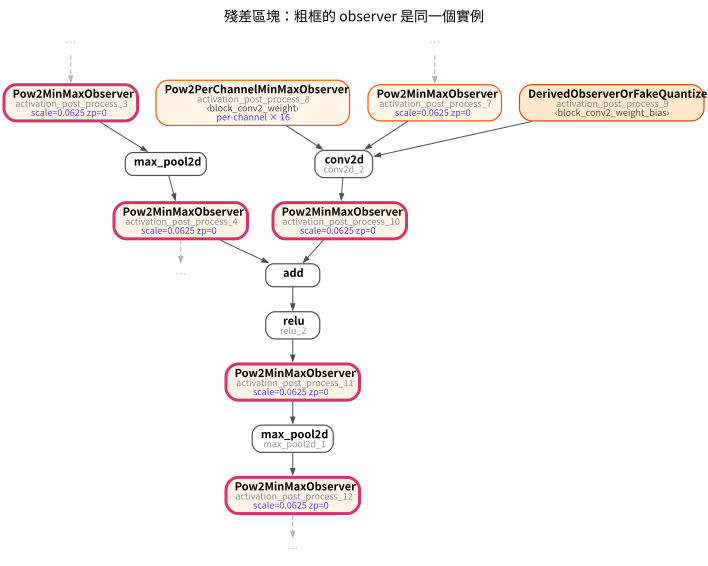

In [8]:
draw(prepared, focus=["max_pool2d", "add", "relu_2", "conv2d_2", "max_pool2d_1"], hops=1,
     highlight=[n.name for n in shared], title="Residual block: the thick-bordered observers are the same instance")

Constraint (6) chains all the way through:

- `add` requires its two inputs (the output of `max_pool2d` and the output of `conv2d_2`) and its output to share one scale; the `relu_2` fused after `add` is its output.
- `max_pool2d` requires input and output to share a scale, so its input (the stem's `relu`) is pulled in too; `max_pool2d_1` likewise.

The price is that tensors with a smaller range also have to use the scale decided by the largest range in the chain. Also, having the same scale does not necessarily mean being tied together:

In [9]:
s_shared = float(shared_mod.calculate_qparams()[0])
by_chance = [g[1][0].args[0].name for g in groups.values()
             if g[0] is not shared_mod and float(g[0].calculate_qparams()[0]) == s_shared]
print(f"Scale of the tied group: 2^{torch.log2(torch.tensor(s_shared)):.0f}; other tensors whose scale happens to be the same: {by_chance}")

被綁在一起的 scale：2^-4；其他 scale 剛好相同的 tensor：['relu_1', 'relu_3']


These tensors have the same scale as that chain, but they have their own observers: powers of 2 are coarse, and they just happen to land in the same bucket. With different calibration data they might differ; the tied chain is always identical.

There is no `batch_norm` on the graph: `prepare_pt2e` first folds BN into conv (M04-1). `adaptive_avg_pool2d` is not in `VPU_OPS`, gets no annotation, and stays in fp32 (M10-3 shows how it cuts the graph apart).

## E. The Q/DQ Graph After `convert_pt2e`

In [10]:
converted = convert_pt2e(prepared)
q = [n for n in qdq_nodes(converted) if n.target == torch.ops.quantized_decomposed.quantize_per_tensor.default]
scales = torch.tensor([float(n.args[1]) for n in q])
pow2 = bool(torch.all(torch.log2(scales) == torch.round(torch.log2(scales))))
zp0 = all(n.args[2] == 0 for n in q)
print(f"{len(q)} quantize_per_tensor: all scales are powers of 2: {pow2}; all zero points are 0: {zp0}")
assert pow2 and zp0

quantize_per_tensor 11 個：scale 全是 2 的冪次 True；zero point 全是 0 True


Finally, compute one SQNR against the fp32 output, only to confirm the model still works (this does not break down how much accuracy each constraint costs). The baseline is the torchao test-version XNNPACKQuantizer with the same calibration data:

In [11]:
xnn = prepare_pt2e(export_module(model, x, dynamic_batch=False), get_xnnpack_quantizer(is_per_channel=True)[0])
xt = make_tensors(n=BATCH, seed=7)[0]
with torch.no_grad():
    for b in calibration_batches(n=64, batch_size=BATCH):
        xnn(*b)
    xnn = convert_pt2e(xnn)
    y = model(xt)
    s_vpu, s_xnn = sqnr(y, converted(xt)), sqnr(y, xnn(xt))
print(f"SQNR vs the fp32 output: MyVPUQuantizer {s_vpu:.1f} dB; XNNPACKQuantizer (torchao test version) {s_xnn:.1f} dB")
assert s_vpu > 15

對 fp32 輸出的 SQNR：MyVPUQuantizer 24.3 dB；XNNPACKQuantizer（torchao 測試版）28.9 dB


## Summary

- A backend Quantizer = hardware constraints translated into annotations: `qscheme` handles symmetric, a custom observer handles the form of the scale, Shared/Derived handle the relations between scales, "don't annotate" handles the op list, and `validate()` handles conditions annotations cannot express (static shape).
- The same-scale requirement chains along add and pool; the cost is borne by the tensors with the smaller ranges.
- All of this is only the Quantizer's own promise. The backend compiler receives nothing but the Q/DQ graph, so it has to check (M10-2) and partition (M10-3) on its own.